<a href="https://colab.research.google.com/github/ClaraMourgueDAlgue/QM2/blob/main/ML_in_QF_final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QF209 — A4 Smart Predict-then-Optimize | Sprint 1
**Karol Wowra; Data, diagnostics, and shared evaluation interface**

This notebook establishes a **fixed, leakage-aware experimental protocol** for all four team members. It is **not** a trained portfolio model. Persons 2–4 will supply prediction tables and/or portfolio weights to the shared backtester.

**Pre-registered starting assumptions:** 20 US-listed ETFs; weekly observations; adjusted close-to-close returns; 5 basis points per dollar traded; an initial risk-controlled long/short interface (max 150% gross leverage); long-only is a subsequent experiment. Training outcomes 2010–2018; validation 2019–2021; reserved holdout 2022–September 2026. Benchmark outputs default to validation, not test.

**Temporal convention:** The feature vector at Friday *t* uses data up to that week's close. Target return is the **next complete Friday-to-Friday week** (*t* to *t+1*). Portfolio weights are conceptually formed at Friday *t* close and earn that next week's total return. This is an idealised close-to-close execution convention; practical close execution after observing the official close is not guaranteed. The 5 bps assumption covers stylised trading friction, not a measured live execution spread. Set a longer signal-to-execution lag in future robustness tests.

**Use:** Run each cell in order in Google Colab. Nothing is downloaded from the internet until the fetch cell. Save the resulting `qf209_a4_outputs.zip` somewhere shared (e.g., Drive/GitHub release). Do not inspect final-test performance until models and protocol are frozen.

In [ ]:
%pip -q install "yfinance>=0.2.55" "pandas>=2.0" "numpy>=1.24" "matplotlib>=3.7" "scipy>=1.10" "statsmodels>=0.14"

In [ ]:
import sys, os, json, platform, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from statsmodels.stats.diagnostic import het_arch

SEED = 209
random.seed(SEED)
np.random.seed(SEED)
OUT = Path('qf209_a4_outputs')
OUT.mkdir(exist_ok=True)

TICKERS = [
    'SPY', 'XLK', 'XLF', 'XLE', 'XLV', 'XLI', 'XLY', 'XLP', 'XLU', 'XLB',
    'QQQ', 'IWM', 'EFA', 'EEM', 'TLT', 'IEF', 'LQD', 'HYG', 'GLD', 'VNQ'
]
GROUPS = {
    'SPY':'US equity', 'XLK':'US equity', 'XLF':'US equity', 'XLE':'US equity',
    'XLV':'US equity','XLI':'US equity','XLY':'US equity','XLP':'US equity',
    'XLU':'US equity','XLB':'US equity','QQQ':'US equity','IWM':'US equity',
    'EFA':'International equity','EEM':'International equity',
    'TLT':'Bonds','IEF':'Bonds','LQD':'Bonds','HYG':'Bonds',
    'GLD':'Gold','VNQ':'Real estate'
}
assert len(TICKERS)==20 and len(set(TICKERS))==20

CONFIG = {
    'ticker_universe': TICKERS,
    'source': 'Yahoo Finance, downloaded via yfinance; auto_adjust=True',
    'daily_start': '2009-01-01', # warmup for features
    'daily_end_exclusive': '2026-10-01', # preserve full weeks through Sep 2026
    'first_target_date': '2010-01-01',
    'train_end_exclusive': '2019-01-01',
    'validation_end_exclusive': '2022-01-01',
    'test_end_inclusive': '2026-09-30',
    'weekly_frequency': 'W-FRI',
    'cost_bps_per_dollar_traded': 5.0,
    'rf_annual_assumption': 0.0, # transparent simplification; sensitivity later
    'allow_short_initially': True,
    'gross_leverage_cap': 1.5,
    'max_weight_abs': 1.0,
    'annualisation_weeks': 52,
    'seed': SEED,
    'show_test_results': False,
}
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| yfinance:', yf.__version__)
print('Configured ETF universe:', TICKERS)

Python: 3.13.16 | pandas: 2.2.3 | yfinance: 0.2.66
Configured ETF universe: ['SPY', 'XLK', 'XLF', 'XLE', 'XLV', 'XLI', 'XLY', 'XLP', 'XLU', 'XLB', 'QQQ', 'IWM', 'EFA', 'EEM', 'TLT', 'IEF', 'LQD', 'HYG', 'GLD', 'VNQ']


## 1. Fetch and freeze adjusted historical prices
`auto_adjust=True` uses Yahoo Finance's adjusted close; no missing weekly prices are forward-filled. Weeks without all 20 asset prices are excluded from the common panel. The code fails loudly if any ticker is missing, avoiding silent changes in the universe.

In [ ]:
def load_adjusted_daily_closes(tickers, start, end_exclusive):
    data = yf.download(
        tickers=tickers, start=start, end=end_exclusive,
        auto_adjust=True, group_by='column',
        progress=False, threads=False, actions=False
    )
    if data.empty:
        raise RuntimeError('Yahoo Finance returned no data. Retry, check connectivity, and check dates.')
    if isinstance(data.columns, pd.MultiIndex):
        # yfinance versions differ in which MultiIndex level contains 'Close'.
        levels_with_close = [i for i in range(data.columns.nlevels)
                             if 'Close' in data.columns.get_level_values(i)]
        if not levels_with_close:
            raise ValueError('Cannot locate adjusted Close in downloaded columns.')
        closes = data.xs('Close', axis=1, level=levels_with_close[0]).copy()
    else:
        if len(tickers) != 1:
            raise ValueError('Expected multi-ticker download to have MultiIndex columns.')
        closes = data[['Close']].rename(columns={'Close':tickers[0]})
    closes.index = pd.to_datetime(closes.index)
    if closes.index.tz is not None:
        closes.index = closes.index.tz_localize(None)
    closes.index = closes.index.normalize()
    closes = closes[~closes.index.duplicated(keep='last')].sort_index()
    closes = closes.reindex(columns=tickers).apply(pd.to_numeric, errors='coerce')
    missing = [t for t in tickers if closes[t].notna().sum()==0]
    if missing:
        raise RuntimeError(f'No adjusted prices for: {missing}; do not silently drop ETFs.')
    if (closes.dropna(how='all') <= 0).any().any():
        raise ValueError('Found non-positive adjusted prices; inspect source data.')
    return closes

DAILY = load_adjusted_daily_closes(TICKERS, CONFIG['daily_start'], CONFIG['daily_end_exclusive'])
last_day = pd.Timestamp(CONFIG['daily_end_exclusive']) - pd.Timedelta(days=1)
last_complete_friday = last_day - pd.Timedelta(days=(last_day.weekday()-4)%7)
WEEKLY = DAILY.resample('W-FRI').last().loc[:last_complete_friday].copy()
weekly_missing = WEEKLY.isna().sum().rename('missing_weeks')
WEEKLY = WEEKLY.dropna(how='any')
if len(WEEKLY)<350:
    raise RuntimeError(f'Too few complete price weeks ({len(WEEKLY)}); review source coverage.')
if not (WEEKLY.index.to_series().diff().dropna()==pd.Timedelta(days=7)).all():
    warnings.warn('Gaps in weekly price index detected. Do NOT treat multi-week changes as 1-week returns!')
    # Strict design: stop, so follow-on annualisation and feature lags are valid.
    raise RuntimeError('Not all Fridays are consecutive; inspect missing-week report.')
WEEKLY.to_csv(OUT/'weekly_adjusted_prices.csv', index_label='week_end')
DAILY.to_csv(OUT/'daily_adjusted_prices.csv', index_label='date')
weekly_missing.to_csv(OUT/'missing_price_weeks_by_ticker.csv')
print('Raw daily rows:', len(DAILY), 'Weekly complete rows:', len(WEEKLY))
print('Complete weekly date range:', WEEKLY.index.min().date(), 'to', WEEKLY.index.max().date())
print('Initial missing weekly prices by ticker:', weekly_missing[weekly_missing>0].to_dict())

Raw daily rows: 4463 Weekly complete rows: 926
Complete weekly date range: 2009-01-02 to 2026-09-25
Initial missing weekly prices by ticker: {}


## 2. Lagged features and future targets
Feature at decision time *t* never uses return from *t+1*. One record = one decision-week and one asset. A `target_end_date` field defines whether the observation belongs to train, validation, or test; splitting on **realization time** avoids having a training label cross the next split boundary.

In [ ]:
FEATURE_COLUMNS = [
    'ret_1w','mom_4w','mom_12w','mom_26w',
    'vol_12w','vol_26w','spy_mom_4w','spy_mom_12w','spy_vol_12w'
]

def build_panel(prices, tickers):
    # Strict consecutive-Friday input keeps these offsets temporally well-defined.
    assert (prices.index.to_series().diff().dropna()==pd.Timedelta(days=7)).all()
    ret = prices.pct_change(fill_method=None)
    forward = ret.shift(-1)
    spy = prices['SPY']
    market_common = pd.DataFrame({
        'spy_mom_4w': spy.pct_change(4, fill_method=None),
        'spy_mom_12w': spy.pct_change(12, fill_method=None),
        'spy_vol_12w': ret['SPY'].rolling(12).std(),
    }, index=prices.index)
    frames = {}
    for ticker in tickers:
        this = pd.DataFrame({
            'ret_1w':ret[ticker],
            'mom_4w':prices[ticker].pct_change(4, fill_method=None),
            'mom_12w':prices[ticker].pct_change(12, fill_method=None),
            'mom_26w':prices[ticker].pct_change(26, fill_method=None),
            'vol_12w':ret[ticker].rolling(12).std(),
            'vol_26w':ret[ticker].rolling(26).std(),
            'target_return':forward[ticker],
        }, index=prices.index)
        this = this.join(market_common)
        this['target_end_date'] = this.index + pd.Timedelta(days=7)
        frames[ticker]=this
    panel = pd.concat(frames, names=['ticker','decision_date']).swaplevel().sort_index()
    panel.index.names=['decision_date','ticker']
    panel = panel.replace([np.inf,-np.inf],np.nan)
    panel = panel.dropna(subset=FEATURE_COLUMNS+['target_return'])
    n = panel.groupby(level='decision_date').size()
    good_dates = n.index[n==len(tickers)]
    panel = panel.loc[panel.index.get_level_values('decision_date').isin(good_dates)]
    panel = panel[panel['target_end_date']>=pd.Timestamp(CONFIG['first_target_date'])]
    if panel.empty:
        raise RuntimeError('Panel empty; check date range and features.')
    return panel

PANEL = build_panel(WEEKLY, TICKERS)
TARGETS = PANEL['target_return'].unstack('ticker').reindex(columns=TICKERS)
TARGET_ENDS = PANEL['target_end_date'].groupby(level='decision_date').first()
assert TARGETS.notna().all().all()
assert (TARGET_ENDS == TARGETS.index+pd.Timedelta(days=7)).all()
assert all(PANEL.groupby(level='decision_date').size()==len(TICKERS))

def date_split(end_dates):
    # Input: target-realization dates, not feature/signal dates.
    d = pd.to_datetime(end_dates)
    train = d < pd.Timestamp(CONFIG['train_end_exclusive'])
    val = (d >= pd.Timestamp(CONFIG['train_end_exclusive'])) & (d < pd.Timestamp(CONFIG['validation_end_exclusive']))
    test = (d >= pd.Timestamp(CONFIG['validation_end_exclusive'])) & (d <= pd.Timestamp(CONFIG['test_end_inclusive']))
    return train, val, test

mask_tr, mask_va, mask_te = date_split(TARGET_ENDS)
SPLIT_DATES = {'train':TARGETS.index[mask_tr], 'validation':TARGETS.index[mask_va], 'test':TARGETS.index[mask_te]}
assert sum(map(len,SPLIT_DATES.values()))==len(TARGETS)
for name, dates in SPLIT_DATES.items():
    if len(dates)==0: raise RuntimeError(f'{name} split is empty')
    subset = PANEL.loc[PANEL.index.get_level_values('decision_date').isin(dates)]
    subset.to_csv(OUT/f'{name}_panel.csv', index_label=['decision_date','ticker'])
    print(f'{name:>10}: {len(dates):>4} weeks, {len(subset):>5} asset-weeks, '
          f'outcomes {TARGET_ENDS.loc[dates].min().date()} to {TARGET_ENDS.loc[dates].max().date()}')
PANEL.to_csv(OUT/'full_feature_target_panel.csv', index_label=['decision_date','ticker'])
TARGETS.to_csv(OUT/'forward_returns.csv', index_label='decision_date')

     train:  470 weeks,  9400 asset-weeks, outcomes 2010-01-01 to 2018-12-28
validation:  157 weeks,  3140 asset-weeks, outcomes 2019-01-04 to 2021-12-31
      test:  247 weeks,  4940 asset-weeks, outcomes 2022-01-07 to 2026-09-25


## 3. Common walk-forward fold generator
**For hyperparameter tuning inside the 2010–2018 training period:** 156 consecutive past weeks train, followed by 26 consecutive internal validation weeks; step 26 weeks. The four latest folds are retained for computational feasibility. No future outcomes ever enter the training fold. This is different from **weekly trading signals** and from a possible later weekly-retrained live system.

In [ ]:
def rolling_folds(target_ends, train_weeks=156, validation_weeks=26, step_weeks=26):
    if min(train_weeks,validation_weeks,step_weeks)<1:
        raise ValueError('Fold lengths and step must be positive.')
    dev = target_ends.loc[target_ends < pd.Timestamp(CONFIG['train_end_exclusive'])]
    dates = dev.index
    for end_training in range(train_weeks, len(dates)-validation_weeks+1, step_weeks):
        tr = dates[end_training-train_weeks:end_training]
        va = dates[end_training:end_training+validation_weeks]
        assert target_ends.loc[tr].max() < target_ends.loc[va].min()
        yield tr,va

FOLDS = list(rolling_folds(TARGET_ENDS))[-4:]  # last four within-training folds
if not FOLDS: raise RuntimeError('Not enough observations for rolling folds.')
fold_info=[]
for i,(tr,va) in enumerate(FOLDS,1):
    fold_info.append({
        'fold':i,'train_start_outcome':str(TARGET_ENDS.loc[tr].min().date()),
        'train_end_outcome':str(TARGET_ENDS.loc[tr].max().date()),
        'validation_start_outcome':str(TARGET_ENDS.loc[va].min().date()),
        'validation_end_outcome':str(TARGET_ENDS.loc[va].max().date()),
    })
pd.DataFrame(fold_info).to_csv(OUT/'walk_forward_fold_schedule.csv', index=False)
print(pd.DataFrame(fold_info).tail(6).to_string(index=False))

 fold train_start_outcome train_end_outcome validation_start_outcome validation_end_outcome
    1          2013-12-27        2016-12-16               2016-12-23             2017-06-16
    2          2014-06-27        2017-06-16               2017-06-23             2017-12-15
    3          2014-12-26        2017-12-15               2017-12-22             2018-06-15
    4          2015-06-26        2018-06-15               2018-06-22             2018-12-14


## 4. Data-universe diagnostics — training outcomes only
**Do not select assets by inspecting test-era correlations or Sharpe.** These plots examine the starting universe; alternative-universe hypotheses should be proposed and compared in validation, with final-test evaluation once.

ARCH-LM is used as evidence of conditional heteroskedasticity in weekly returns, **not** as an asset-selection decision rule or a causal inference test. Endogeneity is not identifiable from simple ETF cross-correlations.

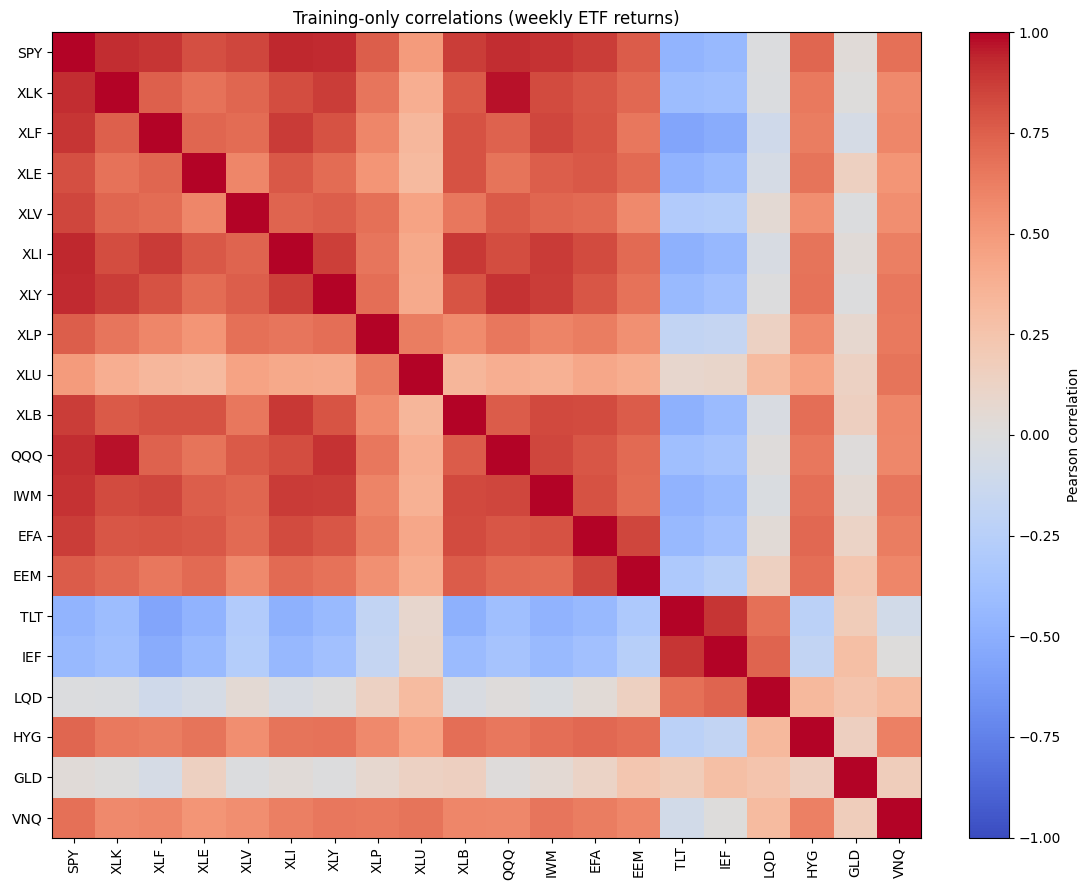

Mean absolute pairwise correlation: 0.527
Training-sample covariance condition number: 8608.4


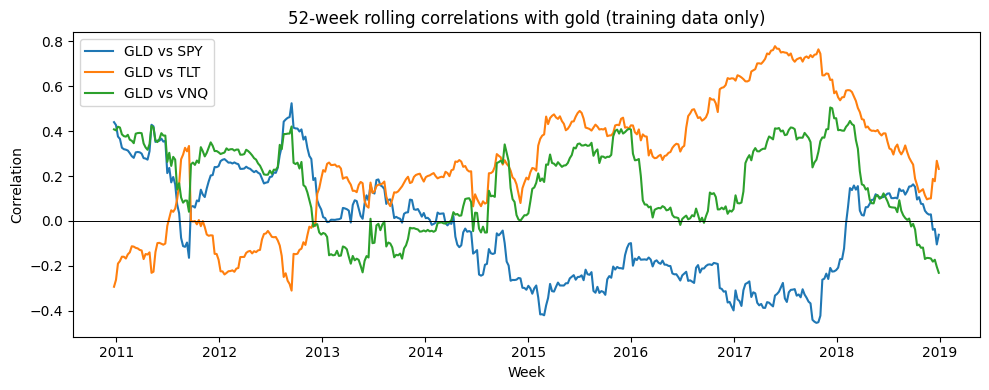

ticker  ARCH_LM  p_value  n_weeks
   SPY  51.1949   0.0000      470
   GLD  67.2826   0.0000      470
   TLT  12.5403   0.0281      470
   VNQ  29.2090   0.0000      470


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [ ]:
TRAIN_RET = WEEKLY.pct_change(fill_method=None).loc[
    (WEEKLY.index>=pd.Timestamp(CONFIG['first_target_date'])) &
    (WEEKLY.index<pd.Timestamp(CONFIG['train_end_exclusive']))
].dropna()
CORR = TRAIN_RET.corr()
CORR.to_csv(OUT/'training_correlations.csv')

fig,ax=plt.subplots(figsize=(11,9))
im=ax.imshow(CORR.values, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
ax.set_xticks(range(len(TICKERS)),TICKERS,rotation=90)
ax.set_yticks(range(len(TICKERS)),TICKERS)
ax.set_title('Training-only correlations (weekly ETF returns)')
fig.colorbar(im, ax=ax, label='Pearson correlation',fraction=.045)
fig.tight_layout()
fig.savefig(OUT/'training_correlation_heatmap.png',dpi=160)
plt.show()

abs_offdiag = np.abs(CORR.values[np.triu_indices(len(TICKERS),k=1)])
cond_number = float(np.linalg.cond(TRAIN_RET.cov().values))
print('Mean absolute pairwise correlation:',round(float(abs_offdiag.mean()),3))
print('Training-sample covariance condition number:',round(cond_number,1))

fig,ax=plt.subplots(figsize=(10,4))
for other in ['SPY','TLT','VNQ']:
    rolling = TRAIN_RET['GLD'].rolling(52).corr(TRAIN_RET[other])
    ax.plot(rolling.index,rolling,label=f'GLD vs {other}')
ax.axhline(0,color='black',linewidth=.7)
ax.set(title='52-week rolling correlations with gold (training data only)',ylabel='Correlation',xlabel='Week')
ax.legend()
fig.tight_layout()
fig.savefig(OUT/'training_gold_rolling_correlations.png',dpi=160)
plt.show()

arch_rows=[]
for tick in ['SPY','GLD','TLT','VNQ']:
    series=(TRAIN_RET[tick]*100).dropna()
    lm,pval,_,_=het_arch(series,nlags=5)
    arch_rows.append({'ticker':tick,'ARCH_LM':float(lm),'p_value':float(pval),'n_weeks':len(series)})
ARCH=pd.DataFrame(arch_rows)
ARCH.to_csv(OUT/'training_arch_lm_tests.csv',index=False)
print(ARCH.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

## 5. Shared weights and performance interface
**All group members must call this same function.** Inputs:
- `weights`: DataFrame indexed by **decision Friday**, columns **exactly** the 20 tickers, every row sums to 1. May include negative values initially (gross leverage ≤ 1.5; individual absolute weight ≤ 1.0).
- `forward_returns`: DataFrame with the same decision-Friday index and ticker columns containing the **next week's** simple total returns.
- `predictions`: optional DataFrame with forecasted next-week simple returns on the same dates/tickers.

The backtester calculates **drift-aware** traded notional: previous holdings after actual market movements compared with the desired new weights. At the start, the portfolio is 100% cash (initial funding trades incur costs). Cost = 0.0005 × sum of absolute dollar-weight changes. Each week's strategy return is `(1-cost_fraction)*(1+gross_portfolio_return)-1`, with fees charged before the period's investment return. Sharpe is annualised using 52 weeks and **zero assumed risk-free rate** for simplicity; change this parameter consistently if adding a weekly risk-free series. `MSE` is asset-week prediction MSE, not a trading-loss metric.

In [ ]:
def evaluate_portfolio(weights, forward_returns, predictions=None,
                       cost_bps=5.0, rf_annual=0.0,
                       allow_short=True, max_gross=1.5, max_weight_abs=1.0):
    if not isinstance(weights,pd.DataFrame) or not isinstance(forward_returns,pd.DataFrame):
        raise TypeError('weights and forward_returns must be pandas DataFrames')
    if weights.empty: raise ValueError('Weights are empty.')
    tickers=list(forward_returns.columns)
    if set(weights.columns)!=set(tickers):
        raise ValueError('Weight columns must exactly equal forward return tickers.')
    if not weights.index.is_unique or not weights.index.is_monotonic_increasing:
        raise ValueError('Weight dates must be unique and increasing.')
    if any(date not in forward_returns.index for date in weights.index):
        raise ValueError('A weight date is missing from forward_returns.')
    if not (weights.index.to_series().diff().dropna()==pd.Timedelta(days=7)).all():
        raise ValueError('Weight dates must be consecutive Fridays; otherwise missed weekly P&L is hidden.')
    wdf = weights.reindex(columns=tickers).astype(float)
    rdf = forward_returns.reindex(index=wdf.index,columns=tickers).astype(float)
    if not (np.isfinite(wdf.to_numpy()).all() and np.isfinite(rdf.to_numpy()).all()):
        raise ValueError('Nonfinite weights or actual returns.')
    if not np.allclose(wdf.sum(axis=1).values,1.0,atol=1e-6):
        raise ValueError('Every portfolio row must sum to 1.0 (fully invested).')
    if (wdf.abs().sum(axis=1)>max_gross+1e-6).any():
        raise ValueError('Weights breach the gross leverage limit.')
    if (wdf.abs()>max_weight_abs+1e-6).any().any():
        raise ValueError('Weights breach per-asset absolute-weight limit.')
    if not allow_short and (wdf < -1e-8).any().any():
        raise ValueError('Negative weights not allowed in long-only experiment.')
    if not 0 <= cost_bps <= 10000: raise ValueError('Invalid cost in basis points.')

    # Pre-trade risky holdings: zero initially (cash), later drifted weights.
    pre_trade = np.zeros(len(tickers),dtype=float)
    records=[]
    fee_rate = cost_bps/10000.0
    for date in wdf.index:
        target = wdf.loc[date].to_numpy(dtype=float)
        r = rdf.loc[date].to_numpy(dtype=float)
        traded_notional = float(np.abs(target-pre_trade).sum())
        cost_fraction = fee_rate*traded_notional
        gross_return = float(np.dot(target,r))
        if 1+gross_return <= 0 or cost_fraction >= 1:
            raise ValueError(f'Invalid portfolio wealth factor at {date}.')
        net_return=(1-cost_fraction)*(1+gross_return)-1
        records.append({'decision_date':date,'gross_return':gross_return,
                        'net_return':net_return,'turnover':traded_notional,
                        'cost_fraction':cost_fraction,
                        'gross_leverage':float(np.abs(target).sum())})
        # Self-financing positions drift after asset moves, before next rebalance.
        pre_trade=target*(1+r)/(1+gross_return)
    series=pd.DataFrame.from_records(records).set_index('decision_date')
    if predictions is not None:
        if set(predictions.columns)!=set(tickers):
            raise ValueError('Prediction columns must match asset universe.')
        if not wdf.index.isin(predictions.index).all():
            raise ValueError('Missing prediction dates.')
        pred=predictions.reindex(index=wdf.index,columns=tickers).astype(float)
        if not np.isfinite(pred.to_numpy()).all():
            raise ValueError('Predictions contain missing/nonfinite values.')
        mse=float(np.mean((pred.to_numpy()-rdf.to_numpy())**2))
    else:
        mse=float('nan')
    rf_weekly=(1+rf_annual)**(1/52)-1
    excess=series['net_return']-rf_weekly
    sd=float(excess.std(ddof=1))
    sharpe=float(np.sqrt(52)*excess.mean()/sd) if sd>0 else float('nan')
    wealth=pd.concat([pd.Series([1.0],index=[wdf.index[0]-pd.Timedelta(days=7)]),
                      (1+series['net_return']).cumprod()]).sort_index()
    max_dd=float((wealth/wealth.cummax()-1).min())
    n=len(series)
    summary={
        'n_weeks':n,
        'ann_return':float((1+series['net_return']).prod()**(52/n)-1),
        'ann_volatility':float(series['net_return'].std(ddof=1)*np.sqrt(52)),
        'sharpe_net':sharpe,
        'max_drawdown':max_dd,
        'mean_weekly_turnover':float(series['turnover'].mean()),
        'total_traded_notional':float(series['turnover'].sum()),
        'total_cost_fraction_sum':float(series['cost_fraction'].sum()),
        'prediction_mse':mse,
        'cost_bps':cost_bps,
    }
    return summary,series,wealth

# Unit tests on known synthetic market paths (no market data needed):
idx=pd.date_range('2020-01-03',periods=3,freq='W-FRI')
synthetic_r=pd.DataFrame({'A':[.10,0.,0.], 'B':[0.,0.,0.]},index=idx)
synthetic_w=pd.DataFrame({'A':[.50,.50,.50], 'B':[.50,.50,.50]},index=idx)
syn_s,syn_period,syn_wealth=evaluate_portfolio(synthetic_w,synthetic_r,cost_bps=5)
assert np.isclose(syn_period.iloc[0]['turnover'],1.0) # cash -> investments
assert np.isclose(syn_period.iloc[1]['turnover'],2*(.55/1.05-.50)) # exact weight drift
assert np.isclose(syn_period.iloc[0]['net_return'], (1-.0005)*(1+.05)-1)
assert syn_s['prediction_mse']!=syn_s['prediction_mse'] # NaN when no forecasts
print('Backtest synthetic unit tests: PASSED')

Backtest synthetic unit tests: PASSED


## 6. Reproducible, model-free benchmarks
These demonstrations run **only on validation** by default; model training and selection should not be influenced by observing test-set performance. The first benchmark rebalances equal weights every week, the second holds 100% SPY throughout. For an equal-weight ETF basket, a weekly rebalancing convention intentionally differs from passive buy-and-hold.

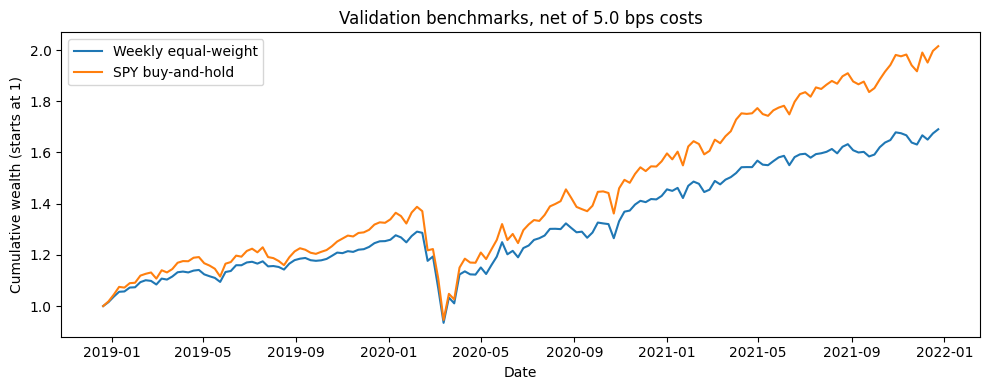

           strategy  sharpe_net  ann_return  ann_volatility  mean_weekly_turnover  max_drawdown  prediction_mse
Weekly equal-weight    1.093330    0.190002        0.173182              0.020401     -0.276197             NaN
   SPY buy-and-hold    1.244715    0.261267        0.203746              0.006369     -0.318290             NaN


In [ ]:
def constant_weight_table(dates,tickers,allocation):
    w=pd.DataFrame(0.0,index=dates,columns=tickers)
    for ticker,weight in allocation.items():
        w[ticker]=float(weight)
    return w

def run_benchmarks(split='validation'):
    if split=='test' and not CONFIG['show_test_results']:
        raise RuntimeError('Final-test results locked. Freeze models, then set show_test_results=True.')
    dates=SPLIT_DATES[split]
    returns=TARGETS.loc[dates]
    choices={
        'Weekly equal-weight':constant_weight_table(dates,TICKERS,{t:1/len(TICKERS) for t in TICKERS}),
        'SPY buy-and-hold':constant_weight_table(dates,TICKERS,{'SPY':1.0}),
    }
    rows=[]; paths={}
    for name,w in choices.items():
        s,period,wealth=evaluate_portfolio(
            w,returns,cost_bps=CONFIG['cost_bps_per_dollar_traded'],
            rf_annual=CONFIG['rf_annual_assumption'],allow_short=False,
            max_gross=1.0,max_weight_abs=1.0)
        rows.append({'strategy':name,**s})
        paths[name]=wealth
        period.to_csv(OUT/f'{split}_{name.lower().replace(" ","_")}_weekly.csv',index_label='decision_date')
    results=pd.DataFrame(rows)
    results.to_csv(OUT/f'{split}_benchmark_metrics.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,4))
    for name,wealth in paths.items():
        ax.plot(wealth.index,wealth.values,label=name)
    ax.set(title=f'{split.capitalize()} benchmarks, net of {CONFIG["cost_bps_per_dollar_traded"]} bps costs',
           ylabel='Cumulative wealth (starts at 1)',xlabel='Date')
    ax.legend(); fig.tight_layout()
    fig.savefig(OUT/f'{split}_benchmark_wealth.png',dpi=160)
    plt.show()
    return results

BENCHMARKS=run_benchmarks('validation')
print(BENCHMARKS[['strategy','sharpe_net','ann_return','ann_volatility',
                  'mean_weekly_turnover','max_drawdown','prediction_mse']].to_string(index=False))

## 7. Model integration contract for teammates
Person 2 (ridge/OLS) produces `predictions` indexed by decision Friday. Their own optimiser produces `weights` at those same dates. Person 3 provides the output weights from their differentiable optimiser; predictions are optional but should be supplied to calculate MSE. Person 4 changes constraints and training objective, **not this function**. Change only `allow_short` and caps as a documented iteration; all experiments use the same dates and cost convention.

```python
# Template — replace with your actual model forecasts and optimiser weights:
# dates = SPLIT_DATES['validation']
# predictions = model_predictions.loc[dates, TICKERS]
# weights = optimiser_weights.loc[dates, TICKERS]
# results, weekly_detail, wealth_curve = evaluate_portfolio(
#     weights, TARGETS.loc[dates], predictions=predictions,
#     cost_bps=5.0, allow_short=True, max_gross=1.5, max_weight_abs=1.0
# )
```

**Important:** `max_gross=1.5` alone is not a trading strategy. The optimiser itself must enforce these feasibility limits; the backtester only validates them. Funding rates for borrow/short, short borrow fees, and ETF-specific spreads are excluded from this baseline and belong in later cost robustness tests.

## 8. Reproducibility, environment, and optional final-test release
Save a manifest with package versions and frozen configuration. After all models/hyperparameters/universe choices are locked, set `CONFIG['show_test_results']=True` and run benchmarks/models **once** on the reserved holdout. Only then should any test-set figure appear in the final report.

In [ ]:
import scipy, statsmodels
MANIFEST={
    'configuration': CONFIG,
    'versions':{'python':sys.version.split()[0],'pandas':pd.__version__,
                'numpy':np.__version__,'yfinance':yf.__version__,
                'scipy':scipy.__version__,'statsmodels':statsmodels.__version__},
    'complete_weekly_observations':len(WEEKLY),
    'first_complete_week':str(WEEKLY.index.min().date()),
    'last_complete_week':str(WEEKLY.index.max().date()),
    'features':FEATURE_COLUMNS,
    'split_weeks':{k:len(v) for k,v in SPLIT_DATES.items()},
    'weekly_price_filling':'none: exclude incomplete weeks',
    'sharpe_convention':'sqrt(52) * mean(weekly_net_return - weekly_rf) / std(weekly_net_return - weekly_rf; ddof=1)',
    'turnover_convention':'sum(abs(new target weights - drifted previous holdings)); 100% cash initially',
}
(OUT/'manifest.json').write_text(json.dumps(MANIFEST,indent=2),encoding='utf-8')
(OUT/'iteration_log.csv').write_text(
    'iteration,date,owner,changed_component,hypothesis,validation_period,validation_sharpe_net,validation_mse,turnover,decision,notes\n'
    '0,,Team,Protocol,Freeze data/splits/metrics before fitting,,, , , ,Pending,\n',encoding='utf-8'
)
README = """QF209 A4 — SPRINT 1 REPRODUCIBILITY

1. Open qf209_a4_sprint1.ipynb in Google Colab; run top-to-bottom.
2. Data are fetched from Yahoo Finance via yfinance. Source: https://finance.yahoo.com/.
3. Inputs: 20 specified tickers. Prices auto_adjust=True. Weekly W-FRI last close; no missing-week filling.
4. Signal at Friday t -> following Friday-to-Friday weekly total return. Execution timing is stylised.
5. Split on OUTCOME dates, not signal dates. Train: 2010–2018; validation 2019–2021; test 2022–Sep 2026.
6. Never use final-test labels/correlations to select assets, features, hyperparameters or models.
7. Internal tuning folds (2010–2018 only): four recent rolling 156w train + 26w validation folds.
   Separate 2019–2021 validation is for choosing group interventions, final 2022+ test reserved.
8. evaluate_portfolio(weights, forward_returns, predictions=None, ...): weights sum to 1,
   columns are all 20 tickers, no NA, max gross 150% for initial long/short experiment.
9. Return: portfolio summary, period detail, cumulative wealth. MSE is per ETF-week if predictions given.
10. Costs: 5bps multiplied by full sum(abs(weight trades)) after position drift.
    Initial acquisition from 100% cash is charged. No borrow/financing/currency taxes.
11. Risk free rate is assumed zero in initial Sharpe computation; disclose and sensitivity test.
12. RUN TEST ONLY AFTER model settings and universe are frozen. Set show_test_results=True then run.
13. CSV and PNG files are outputs. manifest.json captures configuration, package versions.
14. Data caveat: Yahoo prices/adjustments can change; share downloaded CSV snapshot for exact reproduction.
15. Selection caveat: 20 current ETF tickers were chosen retrospectively; acknowledge survivorship/selection bias.
16. Source paper: Costa & Iyengar (2023), Quantitative Finance, DOI: 10.1080/14697688.2023.2236148
"""
(OUT/'README.txt').write_text(README,encoding='utf-8')
import shutil
archive=shutil.make_archive('qf209_a4_outputs','zip',OUT)
print('Generated output archive:',archive)
print('Set CONFIG["show_test_results"] = True only AFTER models and protocol are frozen.')

Generated output archive: /content/qf209_a4_outputs.zip
Set CONFIG["show_test_results"] = True only AFTER models and protocol are frozen.
